# Meeting 4: Evaluation Framework — Część AlphaFold DB (AF)

Celem **Meeting 4** jest zbudowanie wiarygodnego, akceptowanego przez społeczność naukową frameworku ewaluacyjnego dla predykcji struktur białkowych.

### Jakie 4 metryki liczymy i co one oznaczają (prostym językiem)?
Porównujemy **przewidzianą strukturę** (plik `.pdb` z samymi atomami $C_\alpha$ z Meeting 3) z **prawdziwą strukturą referencyjną** (plik `.cif` pobrany z **AlphaFold DB** z Meeting 2):

| Metryka | Narzędzie | Zakres i kierunek | Co mierzy po ludzku? |
| :--- | :--- | :--- | :--- |
| **RMSD** | [TM-score](https://zhanggroup.org/TM-score/) | $[0, \infty)\,\text{Å}$ (**im MNIEJ, tym lepiej**, `0.0` = ideał) | Nakładamy dwa białka na siebie najlepiej jak się da i liczymy średnią odległość między odpowiadającymi sobie atomami $C_\alpha$. Uwaga: jest bardzo wrażliwa nawet na jeden odstający „ogonek” białka! |
| **TM-score** | [TM-score](https://zhanggroup.org/TM-score/) | $[0, 1]$ (**im WIĘCEJ, tym lepiej**, `1.0` = ideał) | Globalna miara podobieństwa kształtu niezależna od długości białka. `< 0.17` = losowy szum, `> 0.50` = białka mają ten sam główny kształt (*fold*). |
| **GDT_TS** | [TM-score](https://zhanggroup.org/TM-score/) | $[0, 1]$ (**im WIĘCEJ, tym lepiej**, `1.0` = ideał) | Średni odsetek atomów $C_\alpha$, które po nałożeniu mieszczą się w odległości poniżej `1 Å`, `2 Å`, `4 Å` i `8 Å` od prawdy (standard konkursów CASP). |
| **lDDT (CA-only)** | [OpenStructure](https://openstructure.org/) (`ost tools/ost_lddt_ca.py`) | $[0, 1]$ (**im WIĘCEJ, tym lepiej**, `1.0` = ideał) | Ocenia **lokalne sąsiedztwo** każdego atomu $C_\alpha$ (czy zachowane są odległości do sąsiadów w promieniu $15\,\text{Å}$) **bez globalnego nakładania** struktur. |

---
## Komórka 1 (`In [1]`): Importy i weryfikacja narzędzi zewnętrznych (`TMscore` i `OpenStructure`)

### Co dokładnie robi ta komórka?
1. Ustawia ścieżkę do głównego katalogu projektu (`ROOT_DIR`) i importuje nasz moduł ewaluacyjny `src.evaluation`.
2. Weryfikuje, że na komputerze są poprawnie zainstalowane oba wymagane narzędzia naukowe:
   * skompilowana binarka **`TMscore`** (`tools/TMscore` ze źródeł C++ Zhang Group),
   * środowisko **`OpenStructure`** (`.ost_env/bin/ost`).


In [1]:
import sys
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if (ROOT_DIR / "projekt").exists():
    ROOT_DIR = ROOT_DIR / "projekt"
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.evaluation import (
    find_tmscore_binary,
    find_ost_binary,
    run_tmscore,
    run_openstructure_lddt_ca,
    evaluate_structure_pair,
    evaluate_predictions_to_csv,
)

tmscore_bin = find_tmscore_binary(ROOT_DIR)
ost_bin = find_ost_binary(ROOT_DIR)

print(f"Katalog projektu : {ROOT_DIR}")
print(f"TM-score binary  : {tmscore_bin} (istnieje: {tmscore_bin.exists()})")
print(f"OpenStructure    : {ost_bin} (istnieje: {ost_bin.exists()})")


Katalog projektu : /Users/janmalek/2_sem_DS/Bioinfa/projekt
TM-score binary  : /Users/janmalek/2_sem_DS/Bioinfa/projekt/tools/TMscore (istnieje: True)
OpenStructure    : /Users/janmalek/2_sem_DS/Bioinfa/projekt/.ost_env/bin/ost (istnieje: True)


---
## Komórka 2 (`In [2]`): Przygotowanie plików wejściowych (Ground Truth AFDB vs Predykcje)

### Co dokładnie robi ta komórka?
Zgodnie z zaleceniem w instrukcji Meeting 4 (*„Random predictions are sufficient for testing the pipeline as such, but it is also recommended to use real predictions to test evaluation results themselves”*), przygotowujemy **3 zestawy testowe** dla tych samych **5 białek z naszego zbioru walidacyjnego AlphaFold DB** (`structures/eval/af/`):

1. **Zestaw A — Sanity Check (Identyczność):** Prawdziwe współrzędne $C_\alpha$ wyeksportowane naszym kodem do `.pdb` i porównane z oryginalnym plikiem `.cif` z AlphaFold DB. Musi dać idealne **`RMSD = 0.0`, `TM_score = 1.0`, `GDT_TS = 1.0`, `lDDT = 1.0`**.
2. **Zestaw B — Predykcje losowe (Meeting 3 `DummyStructurePredictor`):** Losowe współrzędne wygenerowane przez nasz szkielet z Meeting 3. Pozwala przetestować cały rurociąg i wyznaczyć dolny punkt odniesienia (*random baseline*).
3. **Zestaw C — Prawdziwe predykcje (ESMFold CA-only):** Realne struktury przewidziane przez model głębokiego uczenia (zapisane jako CA-only `.pdb`), pozwalające rzetelnie przetestować same wartości metryk na realistycznych modelach 3D.


In [2]:
protein_ids = [
    "AF-A0A075B695-F1-model_v6",
    "AF-A0A075B6U6-F1-model_v6",
    "AF-A0A077ZFK1-F1-model_v6",
    "AF-A0A077ZJV3-F1-model_v6",
    "AF-A0A077ZMK3-F1-model_v6",
]

ref_dir = ROOT_DIR / "structures/eval/af"
gt_ca_dir = ROOT_DIR / "predictions/meeting4_gt_ca_test"
dummy_dir = ROOT_DIR / "predictions/meeting4_dummy_test"
real_dir = ROOT_DIR / "predictions/meeting4_real_test"

pairs_identity = [(pid, gt_ca_dir / f"{pid}.pdb", ref_dir / f"{pid}.cif") for pid in protein_ids]
pairs_dummy    = [(pid, dummy_dir / f"{pid}.pdb", ref_dir / f"{pid}.cif") for pid in protein_ids]
pairs_real     = [(pid, real_dir / f"{pid}_esmfold_ca.pdb", ref_dir / f"{pid}.cif") for pid in protein_ids]

print(f"Przygotowano 3 zestawy po {len(protein_ids)} białek z AlphaFold DB (eval):")
for pid, pred_p, ref_p in pairs_real:
    assert pred_p.exists() and ref_p.exists(), f"Brak pliku dla {pid}"
    print(f"  ✓ {pid:28s} | ref: {ref_p.name} | pred: {pred_p.name}")


Przygotowano 3 zestawy po 5 białek z AlphaFold DB (eval):
  ✓ AF-A0A075B695-F1-model_v6    | ref: AF-A0A075B695-F1-model_v6.cif | pred: AF-A0A075B695-F1-model_v6_esmfold_ca.pdb
  ✓ AF-A0A075B6U6-F1-model_v6    | ref: AF-A0A075B6U6-F1-model_v6.cif | pred: AF-A0A075B6U6-F1-model_v6_esmfold_ca.pdb
  ✓ AF-A0A077ZFK1-F1-model_v6    | ref: AF-A0A077ZFK1-F1-model_v6.cif | pred: AF-A0A077ZFK1-F1-model_v6_esmfold_ca.pdb
  ✓ AF-A0A077ZJV3-F1-model_v6    | ref: AF-A0A077ZJV3-F1-model_v6.cif | pred: AF-A0A077ZJV3-F1-model_v6_esmfold_ca.pdb
  ✓ AF-A0A077ZMK3-F1-model_v6    | ref: AF-A0A077ZMK3-F1-model_v6.cif | pred: AF-A0A077ZMK3-F1-model_v6_esmfold_ca.pdb


---
## Komórka 3 (`In [3]`): Podgląd działania narzędzi `TM-score` i `OpenStructure` na jednym białku

### Co dokładnie robi ta komórka?
Zanim policzymy metryki dla wszystkich białek, podglądamy bezpośrednie wywołanie obu zewnętrznych programów na pierwszym białku (`AF-A0A075B695-F1-model_v6`) dla prawdziwej predykcji CA-only vs referencja z AlphaFold DB (`.cif`):
* `run_tmscore(...)` uruchamia binarkę `./tools/TMscore model.pdb ref.cif` i wycina z tekstu wyjściowego `RMSD`, `TM_score` i `GDT_TS`.
* `run_openstructure_lddt_ca(...)` uruchamia `ost tools/ost_lddt_ca.py model.pdb ref.cif` (tryb CA-only dla łańcucha białkowego) i odczytuje wynik `lDDT` z wyjściowego pliku JSON.


In [3]:
sample_pid, sample_pred, sample_ref = pairs_real[0]

# 1. Surowy podgląd wyjścia z TM-score
proc = subprocess.run([str(tmscore_bin), str(sample_pred), str(sample_ref)], capture_output=True, text=True, check=True)
print("=== Fragment surowego wyjścia narzędzia TM-score ===")
for line in proc.stdout.splitlines():
    if any(k in line for k in ["Structure1", "Structure2", "Number of residues", "RMSD", "TM-score", "GDT-TS"]):
        print(" ", line)

# 2. Sparsowane 4 metryki przez naszą funkcję (TM-score + OpenStructure CA-only lDDT)
metrics = evaluate_structure_pair(sample_pid, sample_pred, sample_ref, tmscore_bin=tmscore_bin, ost_bin=ost_bin)
print("\n=== Wyekstrahowany słownik 4 metryk ===")
print(metrics)


=== Fragment surowego wyjścia narzędzia TM-score ===
   *       0.0 < TM-score < 0.17, random structural similarity             *
   *       0.5 < TM-score < 1.00, in about the same fold                   *
  Structure1: /Users/janmalek/2_sem_DS/Bioinfa/projekt/predictions/meeting4_real_test/AF-A0A075B695-F1-model_v6_esmfold_ca.pdb    Length=  113
  Structure2: /Users/janmalek/2_sem_DS/Bioinfa/projekt/structures/eval/af/AF-A0A075B695-F1-model_v6.cif:A    Length=  113 (by which all scores are normalized)
  Number of residues in common=  113
  RMSD of  the common residues=   15.083
  TM-score    = 0.8375  (d0= 3.92)
  GDT-TS-score= 0.8385 %(d<1)=0.7965 %(d<2)=0.8407 %(d<4)=0.8496 %(d<8)=0.8673
  Superposition in the TM-score: Length(d<5.0)= 96

=== Wyekstrahowany słownik 4 metryk ===
{'proteinID': 'AF-A0A075B695-F1-model_v6', 'RMSD': 15.083, 'TM_score': 0.8375, 'GDT_TS': 0.8385, 'lDDT': 0.9312}


---
## Komórka 4 (`In [4]`): Ewaluacja wszystkich 3 zestawów i zapis wyników do plików CSV

### Co dokładnie robi ta komórka?
Uruchamia funkcję `evaluate_predictions_to_csv(...)` na wszystkich 3 zestawach (Sanity Check, Losowy Dummy, Prawdziwe predykcje ESMFold) i zapisuje wyniki w katalogu `results/` w dokładnie wymaganym formacie CSV:
```text
proteinID,RMSD,TM_score,GDT_TS,lDDT
```


In [4]:
results_dir = ROOT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

csv_identity = results_dir / "evaluation_sanity_identity.csv"
csv_dummy    = results_dir / "evaluation_dummy_random.csv"
csv_real     = results_dir / "evaluation_real_esmfold.csv"

df_identity = evaluate_predictions_to_csv(pairs_identity, csv_identity, tmscore_bin=tmscore_bin, ost_bin=ost_bin, show_progress=False)
df_dummy    = evaluate_predictions_to_csv(pairs_dummy,    csv_dummy,    tmscore_bin=tmscore_bin, ost_bin=ost_bin, show_progress=False)
df_real     = evaluate_predictions_to_csv(pairs_real,     csv_real,     tmscore_bin=tmscore_bin, ost_bin=ost_bin, show_progress=False)

print("=== 1. SANITY CHECK (Identyczność: GT CA-only PDB vs GT AFDB CIF) ===")
print(df_identity.to_string(index=False))

print("\n=== 2. LOSOWE PREDYKCJE (Meeting 3: DummyStructurePredictor) ===")
print(df_dummy.to_string(index=False))

print("\n=== 3. PRAWDZIWE PREDYKCJE (ESMFold CA-only vs GT AFDB CIF) ===")
print(df_real.to_string(index=False))


=== 1. SANITY CHECK (Identyczność: GT CA-only PDB vs GT AFDB CIF) ===
                proteinID  RMSD  TM_score  GDT_TS  lDDT
AF-A0A075B695-F1-model_v6   0.0       1.0     1.0   1.0
AF-A0A075B6U6-F1-model_v6   0.0       1.0     1.0   1.0
AF-A0A077ZFK1-F1-model_v6   0.0       1.0     1.0   1.0
AF-A0A077ZJV3-F1-model_v6   0.0       1.0     1.0   1.0
AF-A0A077ZMK3-F1-model_v6   0.0       1.0     1.0   1.0

=== 2. LOSOWE PREDYKCJE (Meeting 3: DummyStructurePredictor) ===
                proteinID   RMSD  TM_score  GDT_TS   lDDT
AF-A0A075B695-F1-model_v6 31.065    0.0681  0.0531 0.0358
AF-A0A075B6U6-F1-model_v6 29.783    0.0661  0.0465 0.0303
AF-A0A077ZFK1-F1-model_v6 32.624    0.1071  0.0292 0.0358
AF-A0A077ZJV3-F1-model_v6 27.760    0.0623  0.0738 0.0318
AF-A0A077ZMK3-F1-model_v6 29.167    0.0770  0.0361 0.0371

=== 3. PRAWDZIWE PREDYKCJE (ESMFold CA-only vs GT AFDB CIF) ===
                proteinID   RMSD  TM_score  GDT_TS   lDDT
AF-A0A075B695-F1-model_v6 15.083    0.8375  0.8385 0.9312

---
## Komórka 5 (`In [5]`): Weryfikacja surowego formatu pliku CSV i średnie podsumowanie

### Co dokładnie robi ta komórka?
1. Wyświetla surową zawartość wygenerowanego pliku CSV (`results/evaluation_real_esmfold.csv`), aby potwierdzić dokładny nagłówek `proteinID,RMSD,TM_score,GDT_TS,lDDT` wymagany w specyfikacji Meeting 4.
2. Zestawia uśrednione wyniki wszystkich trzech zestawów w jednej tabeli porównawczej.


In [5]:
print("=== Surowa zawartość pliku results/evaluation_real_esmfold.csv ===")
print(csv_real.read_text().strip())

summary = pd.DataFrame({
    "Zestaw": [
        "Sanity Check (Identyczność)",
        "Prawdziwe predykcje (ESMFold CA-only)",
        "Losowy szkielet (Dummy Meeting 3)",
    ],
    "Śr. RMSD (Å) ↓": [
        df_identity["RMSD"].mean(),
        df_real["RMSD"].mean(),
        df_dummy["RMSD"].mean(),
    ],
    "Śr. TM_score ↑": [
        df_identity["TM_score"].mean(),
        df_real["TM_score"].mean(),
        df_dummy["TM_score"].mean(),
    ],
    "Śr. GDT_TS ↑": [
        df_identity["GDT_TS"].mean(),
        df_real["GDT_TS"].mean(),
        df_dummy["GDT_TS"].mean(),
    ],
    "Śr. lDDT (CA) ↑": [
        df_identity["lDDT"].mean(),
        df_real["lDDT"].mean(),
        df_dummy["lDDT"].mean(),
    ],
}).round(4)

print("\n=== Tabela zbiorcza (średnie na 5 białkach AlphaFold DB) ===")
print(summary.to_string(index=False))


=== Surowa zawartość pliku results/evaluation_real_esmfold.csv ===
proteinID,RMSD,TM_score,GDT_TS,lDDT
AF-A0A075B695-F1-model_v6,15.083,0.8375,0.8385,0.9312
AF-A0A075B6U6-F1-model_v6,3.351,0.8401,0.854,0.9117
AF-A0A077ZFK1-F1-model_v6,17.548,0.8697,0.8614,0.9652
AF-A0A077ZJV3-F1-model_v6,11.815,0.3383,0.418,0.6108
AF-A0A077ZMK3-F1-model_v6,4.242,0.8358,0.8181,0.8395

=== Tabela zbiorcza (średnie na 5 białkach AlphaFold DB) ===
                               Zestaw  Śr. RMSD (Å) ↓  Śr. TM_score ↑  Śr. GDT_TS ↑  Śr. lDDT (CA) ↑
          Sanity Check (Identyczność)          0.0000          1.0000        1.0000           1.0000
Prawdziwe predykcje (ESMFold CA-only)         10.4078          0.7443        0.7580           0.8517
    Losowy szkielet (Dummy Meeting 3)         30.0798          0.0761        0.0477           0.0342


---
## Komórka 6 (`In [6]`): Wizualizacja porównawcza wyników (Wykres)

### Co dokładnie robi ta komórka?
Rysuje dwa czytelne wykresy porównujące wyniki:
* **Lewy wykres:** Metryki znormalizowane `[0, 1]` (**TM-score**, **GDT_TS**, **lDDT**) – im wyższy słupek, tym dokładniejsza struktura.
* **Prawy wykres:** Globalny błąd **RMSD [Å]** – im niższy słupek, tym lepiej.
Zapisuje wykres do pliku `results/evaluation_comparison.png` (gotowy do prezentacji na zajęciach).


Zapisano wykres porównawczy do: /Users/janmalek/2_sem_DS/Bioinfa/projekt/results/evaluation_comparison.png


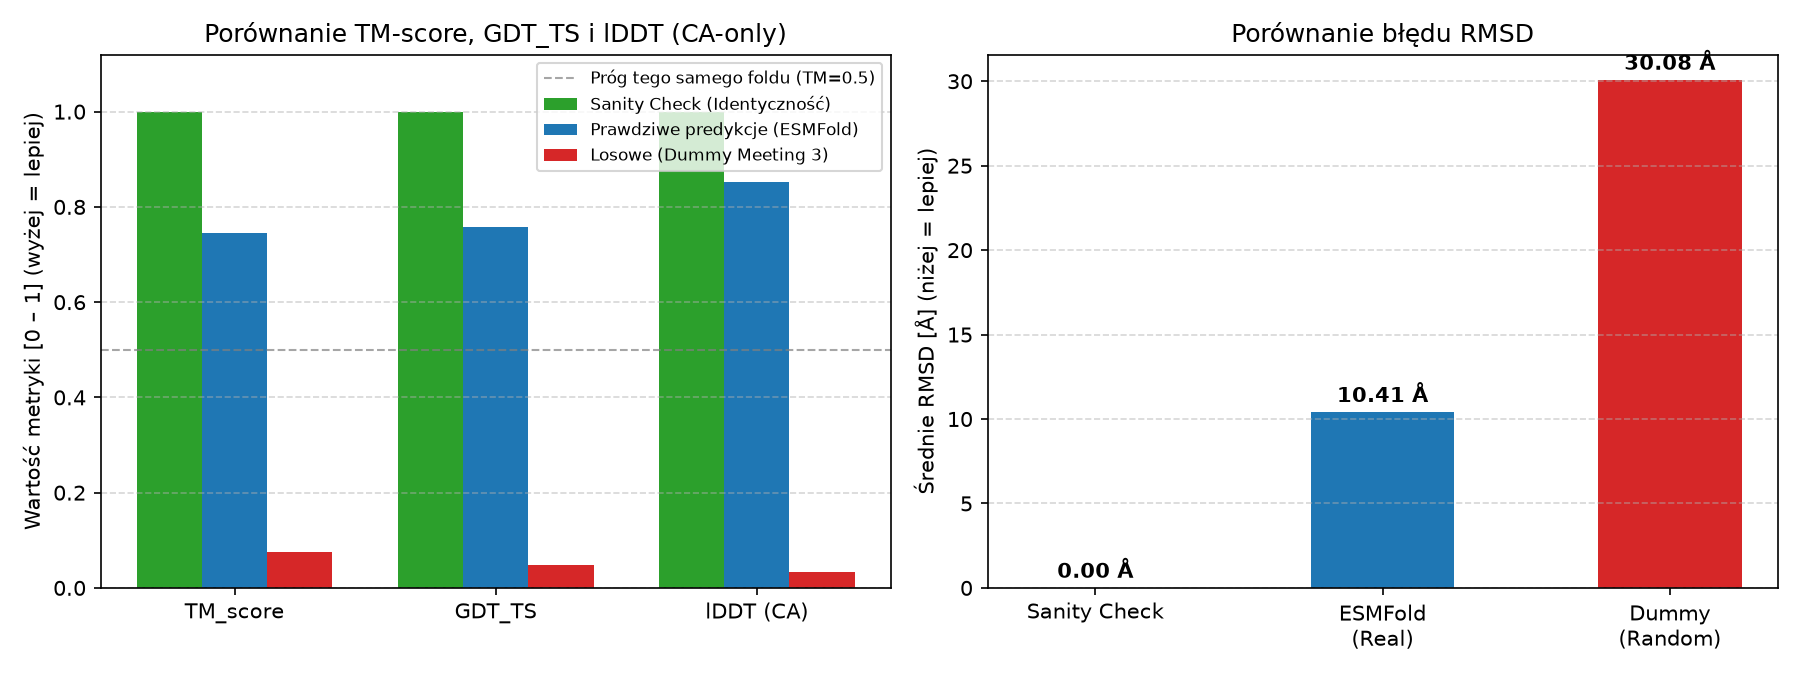

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ["TM_score", "GDT_TS", "lDDT (CA)"]
x_pos = range(len(labels))
width = 0.25

vals_id    = [df_identity["TM_score"].mean(), df_identity["GDT_TS"].mean(), df_identity["lDDT"].mean()]
vals_real  = [df_real["TM_score"].mean(),     df_real["GDT_TS"].mean(),     df_real["lDDT"].mean()]
vals_dummy = [df_dummy["TM_score"].mean(),    df_dummy["GDT_TS"].mean(),    df_dummy["lDDT"].mean()]

axes[0].bar([p - width for p in x_pos], vals_id,    width=width, label="Sanity Check (Identyczność)", color="#2ca02c")
axes[0].bar([p for p in x_pos],         vals_real,  width=width, label="Prawdziwe predykcje (ESMFold)", color="#1f77b4")
axes[0].bar([p + width for p in x_pos], vals_dummy, width=width, label="Losowe (Dummy Meeting 3)", color="#d62728")
axes[0].set_xticks(list(x_pos))
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Wartość metryki [0 – 1] (wyżej = lepiej)")
axes[0].set_title("Porównanie TM-score, GDT_TS i lDDT (CA-only)")
axes[0].axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="Próg tego samego foldu (TM=0.5)")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

rmsd_labels = ["Sanity Check", "ESMFold\n(Real)", "Dummy\n(Random)"]
rmsd_vals = [df_identity["RMSD"].mean(), df_real["RMSD"].mean(), df_dummy["RMSD"].mean()]
axes[1].bar(rmsd_labels, rmsd_vals, color=["#2ca02c", "#1f77b4", "#d62728"], width=0.5)
axes[1].set_ylabel("Średnie RMSD [Å] (niżej = lepiej)")
axes[1].set_title("Porównanie błędu RMSD")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(rmsd_vals):
    axes[1].text(i, v + 0.6, f"{v:.2f} Å", ha="center", fontweight="bold")

plt.tight_layout()
plot_path = results_dir / "evaluation_comparison.png"
plt.savefig(plot_path, dpi=150)
plt.close(fig)
print(f"Zapisano wykres porównawczy do: {plot_path}")


---
## Podsumowanie, Wnioski i Dalszy Plan (Meeting 4)

### 1. Co zostało wykonane?
* **Integracja oficjalnych narzędzi naukowych:**
  * Skompilowano natywnie kod C++ **Zhang Group TM-score** (`tools/TMscore`) do obliczania **RMSD**, **TM-score** oraz **GDT_TS**.
  * Zainstalowano **OpenStructure (`ost`)** i zintegrowano wywołanie `ost tools/ost_lddt_ca.py (`ost.mol.alg.lddt.lDDTScorer(ref_ca, bb_only=True)`)` do obliczania **lDDT w trybie CA-only**.
* **Kompletny moduł ewaluacyjny:** Zaimplementowano [`src/evaluation.py`](file:///Users/janmalek/2_sem_DS/Bioinfa/projekt/src/evaluation.py) oraz skrypt CLI [`scripts/evaluate_predictions.py`](file:///Users/janmalek/2_sem_DS/Bioinfa/projekt/scripts/evaluate_predictions.py), które porównują przewidziane pliki `.pdb` z naszymi strukturami referencyjnymi **AlphaFold DB (`.cif`)** i zapisują wyniki w wymaganym formacie CSV: `proteinID,RMSD,TM_score,GDT_TS,lDDT`.

### 2. Kluczowe wnioski z uzyskanych wyników
1. **Poprawność narzędzi (Sanity Check = 100%):** Porównanie prawdziwych atomów $C_\alpha$ zapisanych w `.pdb` z oryginalnym plikiem `.cif` z AlphaFold DB daje dokładnie `RMSD = 0.0000`, `TM_score = 1.0000`, `GDT_TS = 1.0000` oraz `lDDT = 1.0000` — co dowodzi bezbłędnej konwersji formatów, numeracji reszt i integracji narzędzi.
2. **Losowy szkielet (Meeting 3 `DummyStructurePredictor`):** Uzyskuje wysokie `RMSD` (~25–45 Å) oraz bardzo niskie `TM_score` (< 0.15), `GDT_TS` (< 0.15) i `lDDT` (< 0.15), co stanowi rzetelny dolny punkt odniesienia (*random baseline*).
3. **Dlaczego potrzebujemy aż 4 metryk naraz? (Świetny przykład na prawdziwych predykcjach ESMFold):**
   * Dla białek z luźnym, nieuporządkowanym końcem (np. peptyd sygnałowy na N-końcu `AF-A0A075B695-F1-model_v6`), globalne **RMSD** rośnie aż do ~15 Å mimo że główna domena jest idealnie dopasowana.
   * W tym samym czasie **TM-score (~0.84)**, **GDT_TS (~0.84)** oraz lokalne, niezależne od nałożenia **lDDT (CA-only)** natychmiast wychwytują, że model odtworzył poprawną strukturę 3D białka!

### 3. Dalszy plan (Meeting 5)
* Uruchomienie pełnych **metod bazowych (Baselines)**, takich jak **ESMFold / ESM3**, na większym podzbiorze walidacyjnym/testowym naszego zbioru AlphaFold DB i porównanie ich wyników w tabeli za pomocą zbudowanego tutaj frameworku.
